# Macro Credit Loss Stress

## Alcance y pregunta

¿Agregar un escenario medio reproduce la pérdida multiescenario?

**Laboratorio estructural sintético.** La ampliación semanal sustituye el baseline OLS genérico por un experimento del mecanismo anunciado. No contiene estimaciones de datos de Colombia ni evidencia de desempeño productivo.

## Modelo y mecanismo

$$PD(z)=\operatorname{logit}^{-1}(a+bz),\quad EL=PD\,LGD\,EAD$$

Se simulan exposiciones heterogéneas con PD base logística, LGD que aumenta con stress y escenarios z−1,z,z+1 con pesos .2,.6,.2. Se calcula pérdida ponderada y pérdida en el escenario medio. No se usa producto de medias para agregar cartera.

### Supuestos de identificación

Shock común dado; exposiciones fijas; relaciones PD/LGD impuestas, no estimadas.

La verdad del DGP es conocida por construcción. Recuperar esa verdad comprueba implementación y diseño; no establece que el mecanismo describa una población observada.

## Configuración reproducible

Se usan NumPy, SciPy, Pandas y Matplotlib del entorno de investigación del repositorio. La semilla es fija, todos los cálculos se ejecutan desde los inputs y ninguna celda lee resultados precomputados. OLS incluye intercepto salvo fórmulas que lo excluyen explícitamente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
COLORS=['#245C83','#B56A20','#637843']
SEED=20261018
REPLICATIONS=40

def ols_fit(y, regressors):
    """Intercept included; QR/SVD-backed least squares, no matrix inversion."""
    X=np.column_stack([np.ones(len(y)),regressors])
    coefficients,_,rank,_=np.linalg.lstsq(X,y,rcond=None)
    if rank<X.shape[1]: raise ValueError('Diseño sin rango completo')
    return coefficients,y-X@coefficients

def ar_process(rng,n,rho):
    if abs(rho)>=1: raise ValueError('Se requiere AR estacionario')
    draws=rng.normal(size=n+200); x=np.zeros(n+200)
    for t in range(1,len(x)): x[t]=rho*x[t-1]+draws[t]
    return x[200:]


## Datos y experimento

Se simulan exposiciones heterogéneas con PD base logística, LGD que aumenta con stress y escenarios z−1,z,z+1 con pesos .2,.6,.2. Se calcula pérdida ponderada y pérdida en el escenario medio. No se usa producto de medias para agregar cartera.

El siguiente código define el DGP o problema de equilibrio y sus comparadores. Las restricciones, oráculos analíticos y condiciones de factibilidad que corresponden al mecanismo se comprueban dentro de la función. Las cantidades monetarias se expresan en unidades sintéticas.

In [2]:
def experiment(rng,level,n=1000):
    from scipy.special import expit
    intercept=rng.normal(-3,.5,n);ead=rng.lognormal(5,.5,n)
    def loss(z):return np.sum(expit(intercept+.8*z)*np.clip(.4+.06*z,0,1)*ead)
    mixture=.2*loss(level-1)+.6*loss(level)+.2*loss(level+1)
    central=loss(level)
    return {'EL multiescenario':mixture,'EL escenario medio':central,'Diferencia de agregación':mixture-central},(ead,expit(intercept+.8*level))


### Un escenario reproducible

Cada métrica conserva su denominador y unidad conceptual; no se mezclan conteos, probabilidades y costos en un mismo eje. La tabla muestra el caso central de la malla, antes de resumir réplicas.

In [3]:
GRID=[0, 0.5, 1, 1.5, 2]
METRICS=['EL multiescenario', 'EL escenario medio', 'Diferencia de agregación']
central=GRID[len(GRID)//2]
example,diagnostic=experiment(np.random.default_rng(SEED),central)
display(pd.DataFrame({'Métrica':list(example),'Valor':list(example.values())}))
print('Escenario central:',central,'; semilla:',SEED)


Escenario central: 1 ; semilla: 20261018


,Métrica,Valor
0,EL multiescenario,9475.215238
1,EL escenario medio,8470.008838
2,Diferencia de agregación,1005.206400


## Sensibilidad y variación entre réplicas

**Eje:** Stress macro central z.

Se conservan 40 réplicas por escenario. Se reinicia la misma secuencia de semillas para cada nivel: las comparaciones entre niveles comparten innovaciones cuando la dimensión del DGP lo permite. En mecanismos deterministas los cuantiles coinciden; esto no representa una incertidumbre estimada de parámetros. No se descartan resultados desfavorables.

In [4]:
records=[]
for level in GRID:
    for replicate in range(REPLICATIONS):
        metrics,_=experiment(np.random.default_rng(SEED+replicate),level)
        if set(metrics)!=set(METRICS): raise AssertionError('Métricas inconsistentes')
        for name,value in metrics.items():
            if not np.isfinite(value):raise ArithmeticError(f'Resultado no finito: {name}')
            records.append({'nivel':level,'replica':replicate,'metrica':name,'valor':float(value)})
raw=pd.DataFrame(records)
summary=raw.groupby(['nivel','metrica'],sort=False).valor.agg(
    media='mean',mediana='median',sd_replicas='std',
    q025=lambda x:x.quantile(.025),q975=lambda x:x.quantile(.975),n='size').reset_index()
summary['se_media_mc']=summary.sd_replicas/np.sqrt(summary.n)
display(summary.round(5))


,nivel,metrica,media,mediana,sd_replicas,q025,q975,n,se_media_mc
0,0.0,EL multiescenario,4070.55696,4064.57545,91.31826,3942.68503,4245.01552,40,14.43868
1,0.0,EL escenario medio,3528.18345,3523.27019,80.62025,3417.17125,3682.14512,40,12.74718
2,0.0,Diferencia de agregación,542.37350,542.78770,10.90690,525.51378,562.87040,40,1.72453
3,0.5,EL multiescenario,6238.11583,6228.20790,136.48462,6042.42018,6498.79298,40,21.58011
4,0.5,EL escenario medio,5482.99759,5474.97871,122.65529,5311.00438,5717.28244,40,19.39350
5,0.5,Diferencia de agregación,755.11823,755.89667,14.38307,729.06013,781.51054,40,2.27416
6,1.0,EL multiescenario,9369.75637,9356.46954,198.91323,9075.54598,9749.13519,40,31.45094
7,1.0,EL escenario medio,8369.88043,8356.58644,182.20291,8107.81812,8717.65361,40,28.80881
8,1.0,Diferencia de agregación,999.87595,999.09075,18.06554,960.83321,1031.48158,40,2.85641
9,1.5,EL multiescenario,13746.75851,13736.24193,281.97294,13313.24026,14282.85787,40,44.58384


### Qué muestran los intervalos

Las bandas de la figura son cuantiles 2.5–97.5% entre realizaciones del DGP, **no intervalos de confianza de un estimador en una sola muestra**. `se_media_mc` mide únicamente el error Monte Carlo de la media en este conjunto de réplicas; no mide incertidumbre económica ni corrige especificación. Se informa media y mediana para detectar asimetría, especialmente bajo identificación débil.

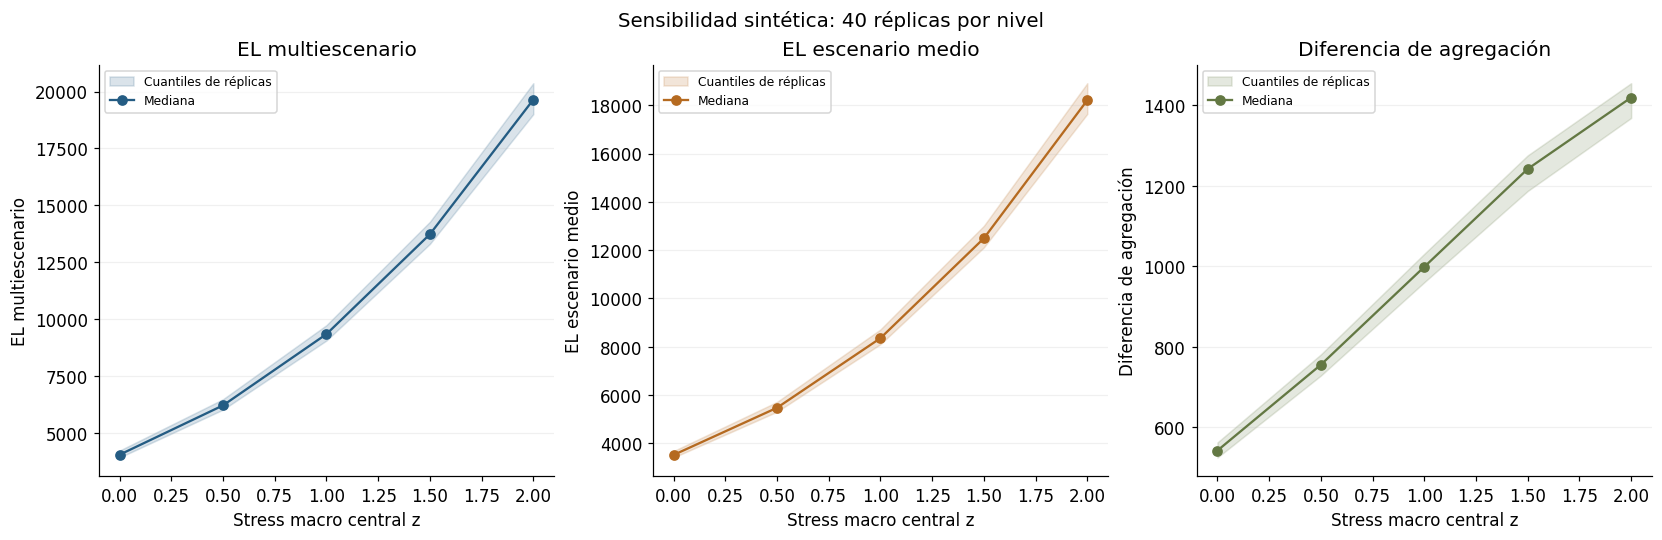

In [5]:
import textwrap
fig,axes=plt.subplots(1,len(METRICS),figsize=(15,4.8),layout='constrained')
for index,(ax,name) in enumerate(zip(np.atleast_1d(axes),METRICS)):
    group=summary[summary.metrica==name].sort_values('nivel')
    ax.fill_between(group.nivel,group.q025,group.q975,color=COLORS[index%3],alpha=.17,label='Cuantiles de réplicas')
    ax.plot(group.nivel,group.mediana,'o-',color=COLORS[index%3],label='Mediana')
    ax.set(title='\n'.join(textwrap.wrap(name,25)),xlabel='\n'.join(textwrap.wrap('Stress macro central z',30)),ylabel=name)
    ax.grid(axis='y',alpha=.18); ax.legend(fontsize=8)
fig.suptitle('Sensibilidad sintética: 40 réplicas por nivel',fontsize=13)
plt.show()


## Lectura de resultados ejecutados

El contraste siguiente se calcula con las salidas de la ejecución, sin fijar de antemano el signo de la conclusión. Debe interpretarse junto con los supuestos y la variación entre réplicas.

In [6]:
for name in METRICS:
    group=summary[summary.metrica==name].sort_values('nivel')
    first,last=group.iloc[0],group.iloc[-1]
    print(f"{name}: mediana {first['mediana']:.6g} en nivel {first['nivel']:g}; "
          f"{last['mediana']:.6g} en nivel {last['nivel']:g}.")
    print(f"  Último escenario: cuantiles [{last['q025']:.6g}, {last['q975']:.6g}], "
          f"media {last['media']:.6g}, error MC de la media {last['se_media_mc']:.3g}.")


EL multiescenario: mediana 4064.58 en nivel 0; 19643.3 en nivel 2.
  Último escenario: cuantiles [19006.4, 20364.4], media 19630.7, error MC de la media 61.4.
EL escenario medio: mediana 3523.27 en nivel 0; 18207.4 en nivel 2.
  Último escenario: cuantiles [17637.1, 18910.6], media 18211, error MC de la media 58.4.
Diferencia de agregación: mediana 542.788 en nivel 0; 1419.65 en nivel 2.
  Último escenario: cuantiles [1368.91, 1455.25], media 1419.71, error MC de la media 3.95.


## Comprobaciones y controles

La reproducibilidad exige que la misma semilla reconstruya las mismas métricas. Los asserts estructurales de la función no dependen de que un estimador estocástico gane a otro en esta realización. Los conteos se reconcilian para no perder réplicas silenciosamente.

In [7]:
repeated,_=experiment(np.random.default_rng(SEED),central)
assert all(np.isclose(example[k],repeated[k],rtol=0,atol=1e-12) for k in METRICS)
assert len(raw)==len(GRID)*REPLICATIONS*len(METRICS)
assert summary.n.eq(REPLICATIONS).all()
assert (summary.q025<=summary.mediana+1e-12).all()
assert (summary.mediana<=summary.q975+1e-12).all()
print('Semilla, finitud, cuantiles y totalidad de réplicas: correctos.')


Semilla, finitud, cuantiles y totalidad de réplicas: correctos.


## Límites y siguiente contraste

No se proyecta mora ni capital regulatorio; falta dependencia de default, amortización y calibración macro.

Antes de incorporar datos observados se debe fijar unidad de análisis, fecha de disponibilidad, reglas de exclusión y población de evaluación. La ampliación demuestra un mecanismo acotado; no convierte el proyecto en modelo validado externamente.

## Trazabilidad

Desarrollo semanal sobre `865c326`, revisión del 18-10-2026 UTC (noche del 17-10 en Colombia). El historial Git conserva el baseline genérico anterior. Todos los datos nuevos se regeneran desde la función `experiment`; las salidas del notebook se guardan después de ejecutar sus celdas de principio a fin.